# 4. 모델 학습 및 성능 비교

서울시 따릉이 일별 수요 예측. [요구사항](../../docs/ml/REQUIREMENTS.md).

In [1]:
from pathlib import Path
import sys, json, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parents[1]
sys.path.insert(0, str(ROOT))
from src.ml.features import FEATURES, load_daily, make_features
from src.ml.splits import split_data, time_cv
from src.ml.models import model_candidates
from src.ml.evaluation import metrics, compare, grouped_metrics
from sklearn.base import clone
from sklearn.inspection import permutation_importance

plt.rcParams.update({"figure.figsize": (10, 4), "font.family": "Malgun Gothic", "axes.unicode_minus": False})
OUT = ROOT / "outputs/ml"
OUT.mkdir(parents=True, exist_ok=True)
LOCAL = ROOT / "data/processed"
LOCAL.mkdir(parents=True, exist_ok=True)
daily = load_daily(ROOT)
frame = make_features(daily)
train, validation, final_train, test = split_data(frame)


,MAE,RMSE,WAPE,R2,fit_seconds
model,,,,,
train_mean,33559.6833,41662.5338,0.3607,-0.2307,NaN
lag_7,27382.0870,41039.1056,0.2943,-0.1942,NaN
ridge,21651.2514,31433.4968,0.2327,0.2994,0.0707
random_forest,27745.6124,36518.0147,0.2982,0.0544,0.1607


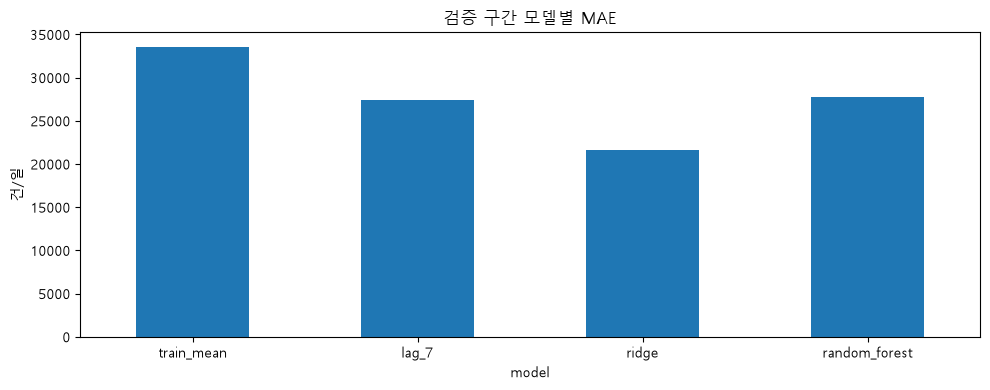

In [2]:
predictions = {"train_mean": np.full(len(validation), train.rentals.mean()), "lag_7": validation.lag_7.to_numpy()}
elapsed = {}
for name, model in model_candidates().items():
    started = time.perf_counter()
    model.fit(train[FEATURES], train.rentals)
    elapsed[name] = time.perf_counter() - started
    predictions[name] = model.predict(validation[FEATURES])
comparison = compare(validation, predictions)
comparison["fit_seconds"] = pd.Series(elapsed)
comparison.to_csv(OUT / "04_models.csv")
display(comparison.round(4))
comparison.MAE.plot.bar(title="검증 구간 모델별 MAE", ylabel="건/일", rot=0)
plt.tight_layout()
plt.savefig(OUT / "04_comparison.png", dpi=120)
plt.show()


- 동일한 검증 날짜에서 ridge의 MAE가 21,651건으로 가장 낮음.
- Ridge는 선형 관계, Random Forest는 비선형·상호작용을 비교하기 위해 선정함.
- 이 결과는 고정 기본 설정의 비교이며 최종 모델은 다음 단계의 시간순 CV로 선정함.